# Red Cedar — Quantum Model and Random Forest

The random forest is the classical baseline for the quantum model: comparing the two on the same data shows what the quantum model does well and where it falls short. Red Cedar trains both on the same training rows and tests them on the same held-out rows, so their results can be compared directly.

The steps:
1. Train both models on the same file
2. Classify the same samples with both
3. Look at the samples where they disagree
4. Compare the features each relies on

The data is the Quick Start's (`01_quick_start.ipynb`): the Wisconsin breast cancer dataset (WDBC), `M` for malignant or `B` for benign. This is a demonstration on a public dataset, not a medical tool, and one dataset: on others the comparison can come out differently. It needs a Red Cedar server of version 2.0 or later.

In [1]:
# The data files described above
train_file = "data/wdbc_train.csv"                 # 455 classified samples (diagnosis known), to train on
unclassified_file = "data/wdbc_unclassified.csv"   # 114 samples, measurements only: diagnosis not yet known

In [2]:
import redcedar

# Connect to a Red Cedar server: the one in REDCEDAR_URL (with the key in REDCEDAR_API_KEY)
# if those are set, otherwise the one on this machine, http://127.0.0.1:8002
client = redcedar.connect()
print(client.status())

# To choose a server in the code instead:
# client = redcedar.connect(url="https://your-server/api", api_key="your-key")

{'ok': True, 'server_version': 'unknown (not a git checkout, no VERSION file)', 'sdk_version': '0.94.0'}


## 1. Train both models on the same file

The quantum model with the Quick Start's settings, and a random forest with its default settings (`06_random_forest.ipynb` explains them). Both get the same 80% of the rows to train on and the same 20% to be tested on.

In [3]:
quantum = client.training.run(train_file, verbose=True, settings={
    "num_qubits": 6,
    "min_layers": 1,
    "max_layers": 2,
    "seed": 123,
    "dimension_reduction": "none",   # keep the original measurements, for section 4
})
forest = client.training.run(train_file, verbose=True, settings={
    "model": "random_forest",
    "seed": 123,
})

last_layer = max(quantum["validation"])
print(f"\nTest accuracy on the same {forest['test_samples']} rows:")
print(f"  Quantum model (layer {last_layer}): {quantum['validation'][last_layer]['test_accuracy']:.1%}"
      f"   (trained in {quantum['elapsed_seconds']}s)")
print(f"  Random forest:            {forest['test_accuracy']:.1%}   (trained in {forest['elapsed_seconds']}s)")

  [  5%] Starting: layers 1-2

  [  5%] Layer 1/2           

  [  5%] Layer 1/2 .


  Layer 1: test accuracy 85.7%


  [ 50%] Layer 2/2

  [ 50%] Layer 2/2 .

... (6 outputs left out)

  [ 20%] Fitting 300 trees...

  [ 80%] Testing...          

  [100%] Done.     



Test accuracy on the same 91 rows:
  Quantum model (layer 2): 85.7%   (trained in 11.7s)
  Random forest:            94.5%   (trained in 0.422s)


## 2. Classify the same samples with both

Both models classify the 114 samples in `wdbc_unclassified.csv`; their actual diagnoses, in `data/wdbc_unclassified_actual.csv`, show how many each gets right, class by class.

                      Correct   Malignant (M)   Benign (B)
  Quantum model    104 of 114        42 of 42     62 of 72
  Random forest    109 of 114        37 of 42     72 of 72


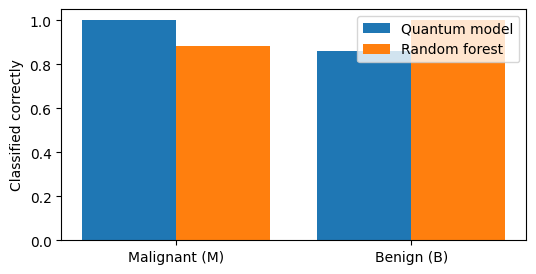

In [4]:
import csv
import matplotlib.pyplot as plt

CLASS_NAMES = {"M": "Malignant (M)", "B": "Benign (B)"}
with open("data/wdbc_unclassified_actual.csv", newline="") as f:
    actual = [row["diagnosis"] for row in csv.DictReader(f)]

predicted = {
    "Quantum model": client.inference.run(quantum["train_id"], unclassified_file)["predictions"],
    "Random forest": client.inference.run(forest["train_id"], unclassified_file)["predictions"],
}

print(f"  {'':14}  {'Correct':>11}  {'Malignant (M)':>14}  {'Benign (B)':>11}")
right = {}
for name, rows in predicted.items():
    labels = [str(r["prediction"]) for r in rows]
    right[name] = {c: sum(p == a == c for p, a in zip(labels, actual)) for c in CLASS_NAMES}
    total = f"{sum(right[name].values())} of {len(actual)}"
    m = f"{right[name]['M']} of {actual.count('M')}"
    b = f"{right[name]['B']} of {actual.count('B')}"
    print(f"  {name:14}  {total:>11}  {m:>14}  {b:>11}")

# Correct per class, both models
x = range(len(CLASS_NAMES))
plt.figure(figsize=(6, 3))
for i, name in enumerate(predicted):
    share = [right[name][c] / actual.count(c) for c in CLASS_NAMES]
    plt.bar([p + 0.4 * i for p in x], share, width=0.4, label=name)
plt.xticks([p + 0.2 for p in x], list(CLASS_NAMES.values()))
plt.ylabel("Classified correctly")
plt.ylim(0, 1.05)
plt.legend()
plt.show()

## 3. Where the models disagree

The samples the two models classify differently, with each model's confidence (the probability it gives its class; for the forest, the share of its trees that voted for it) and the actual class.

In [5]:
q_rows, f_rows = predicted["Quantum model"], predicted["Random forest"]
disagree = [i for i, (q, f) in enumerate(zip(q_rows, f_rows)) if str(q["prediction"]) != str(f["prediction"])]
print(f"The models disagree on {len(disagree)} of {len(actual)} samples:\n")
print(f"  {'Sample':>6}  {'Quantum model':<16}  {'Random forest':<16}  Actual")
for i in disagree:
    q, f = str(q_rows[i]["prediction"]), str(f_rows[i]["prediction"])
    print(f"  {i + 1:>6}  {q} ({q_rows[i]['probabilities'][q]:.0%}){'':9}  "
          f"{f} ({f_rows[i]['probabilities'][f]:.0%}){'':9}  {actual[i]}")

The models disagree on 15 of 114 samples:

  Sample  Quantum model     Random forest     Actual
       8  M (72%)           B (55%)           M
      13  M (72%)           B (84%)           M
      17  M (72%)           B (68%)           M
      20  M (72%)           B (58%)           M
      26  M (72%)           B (88%)           B
      28  M (72%)           B (51%)           B
      33  M (51%)           B (95%)           B
      47  M (51%)           B (99%)           B
      58  M (59%)           B (97%)           B
      67  M (72%)           B (70%)           B
      72  M (72%)           B (62%)           B
      75  M (72%)           B (80%)           M
      90  M (59%)           B (92%)           B
      96  M (59%)           B (97%)           B
     112  M (72%)           B (91%)           B


## 4. The features each model relies on

Explainable AI gives the quantum model's importance for each feature (for a feature on more than one data qubit, the probability that any of its qubits reads 1), and the forest's importance for each column (its share of the trees' error reduction). The two measure different things, so compare which features come first rather than the numbers.

  Quantum model                   Random forest
  worst_perimeter         57.5%  worst_perimeter         17.2%
  worst_radius            23.4%  worst_area              13.7%
  worst_area              14.7%  worst_radius            11.0%
  mean_concave_points     12.2%  mean_concave_points      9.5%
  worst_concave_points     8.8%  worst_concave_points     8.5%


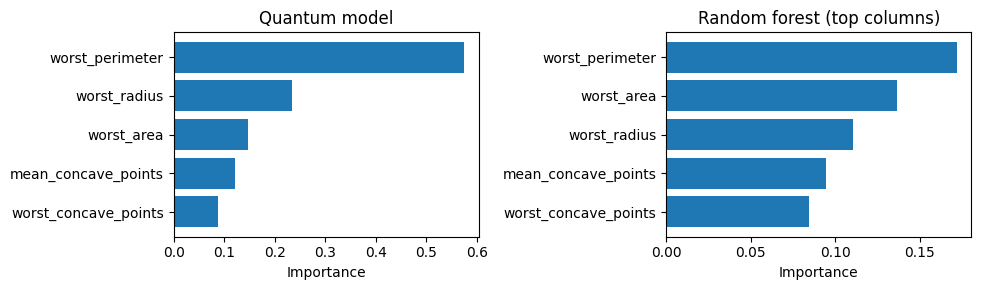

In [6]:
q_features = client.explainable.run(quantum["train_id"])["feature_importances"]   # most important first
f_features = client.explainable.run(forest["train_id"])["feature_importances"][:len(q_features)]

print(f"  {'Quantum model':<30}  Random forest")
for q, f in zip(q_features, f_features):
    print(f"  {q['feature_name']:<22} {q['importance']:>6.1%}  {f['feature_name']:<22} {f['importance']:>6.1%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, title, rows in ((axes[0], "Quantum model", q_features),
                        (axes[1], "Random forest (top columns)", f_features)):
    ax.barh([r["feature_name"] for r in rows], [r["importance"] for r in rows])
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

## Next steps

- Try it on your own file: train both with the same `train_file`, and compare as above.
- `06_random_forest.ipynb`: the random forest on its own, and its settings
- `quantum_and_forest.py`: the same comparison from the command line